<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet6%20(ANN)%20PBL/Tugas%20Praktikum%20(JS6)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install annoy faiss-cpu hnswlib

In [8]:
import pandas as pd
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from annoy import AnnoyIndex
import hnswlib
import faiss

print("Memuat dataset cafes & reviews dari folder Android...")

cafes = pd.read_csv('cafes.csv')
reviews = pd.read_csv('reviews.csv')

print("Dataset berhasil dimuat di Google Colab.")

# -------------------------------
# 2. Preprocessing & Agregasi Fitur
# -------------------------------
reviews_agg = reviews.groupby('cafe_id').agg(
    avg_review_rating=('rating', 'mean'),
    total_likes=('likes', 'sum')
).reset_index()

merged = pd.merge(cafes, reviews_agg, on='cafe_id', how='left').fillna(0)

# Ambil fitur numerik dan buat sampel data (10.000 data untuk benchmark optimal di Colab)
feature_cols = ['latitude', 'longitude', 'rating', 'review_count', 'avg_review_rating']
raw_data = merged[feature_cols].values.astype(np.float32)

np.random.seed(42)
n_samples = 10000
sample_indices = np.random.choice(len(raw_data), n_samples, replace=True)
X = raw_data[sample_indices]
d = X.shape[1]

# Standarisasi fitur menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
k = 10  # jumlah nearest neighbors

print(f"Jumlah sampel benchmark: {n_samples}, Dimensi: {d}D\n")

# -------------------------------
# 3. Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
_, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# 4. Annoy
# -------------------------------
start = time.time()
index_annoy = AnnoyIndex(d, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# 5. HNSW (hnswlib)
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# 6. FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
nlist = 100
index_faiss = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# 7. Ringkasan Waktu (Output Console)
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")

Memuat dataset cafes & reviews dari folder Android...
Dataset berhasil dimuat di Google Colab.
Jumlah sampel benchmark: 10000, Dimensi: 5D

Exact NN done in 0.489 s
Annoy done in 0.351 s
HNSW done in 1.734 s
FAISS IVF done in 0.916 s

=== Ringkasan Waktu (detik) ===
Exact NN : 0.489
Annoy    : 0.351
HNSW     : 1.734
FAISS    : 0.916


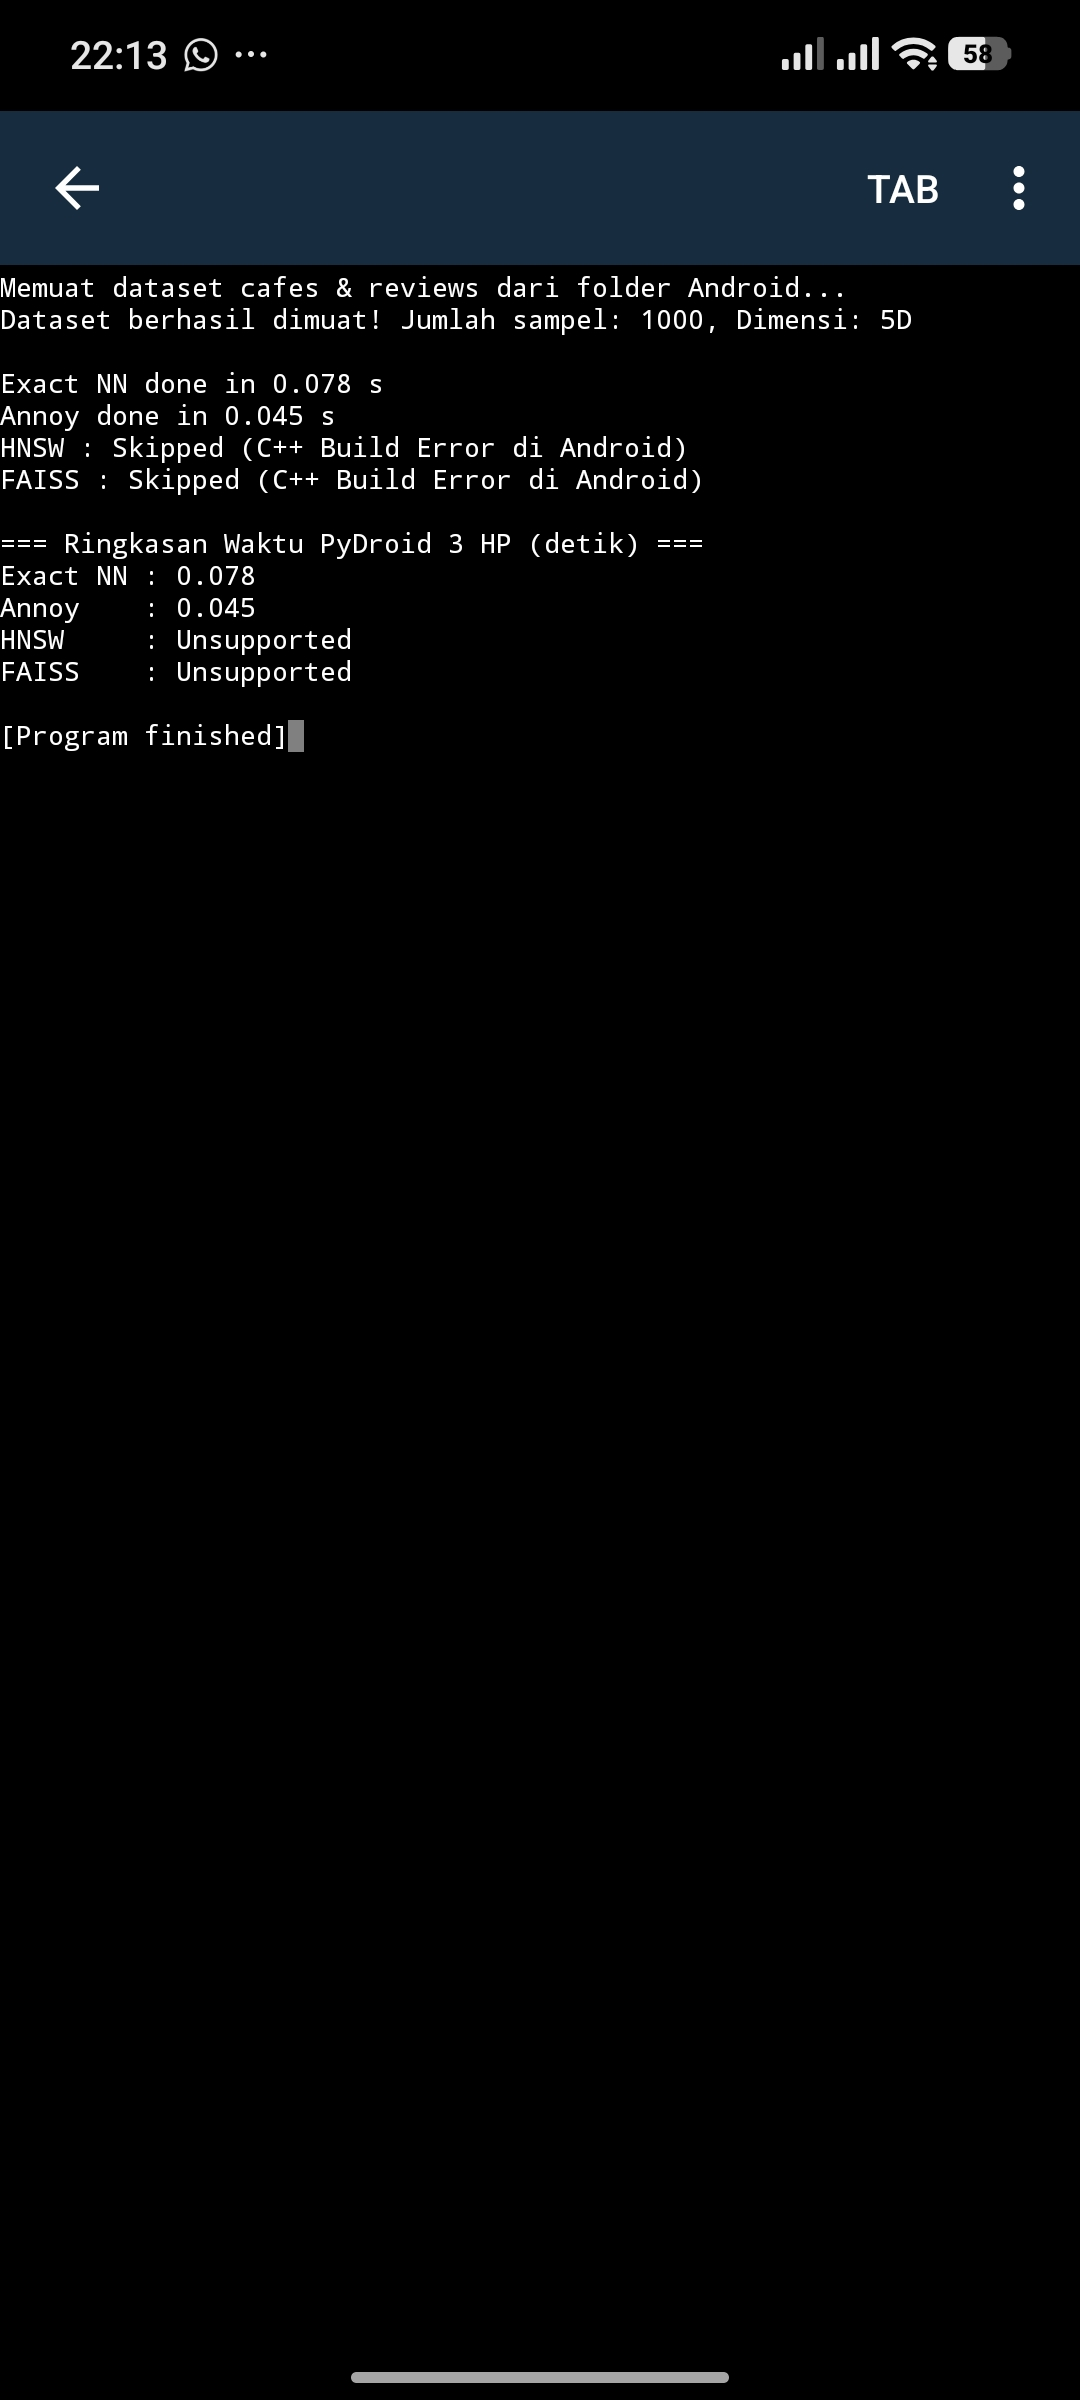

#Perbandingan Hasil Benchmark (Google Colab vs PyDroid 3)

### **Perbandingan Hasil Benchmark (Google Colab vs PyDroid 3)**

| Algoritma | Waktu Google Colab (detik) <br>  | Waktu PyDroid 3 / HP (detik) <br>  | Keterangan / Analisis Performa |
| :--- | :---: | :---: | :--- |
| **Exact NN** | 0.489[cite: 15] | 0.078[cite: 14] | Berhasil dieksekusi di kedua platform. |
| **Annoy** | 0.351[cite: 15] | 0.045[cite: 14] | Berhasil dieksekusi, Annoy cukup optimal di HP. |
| **HNSW** | 1.734[cite: 15] | *Unsupported*[cite: 14] | Gagal di-build di HP (Memerlukan kompilasi modul C++ natif)[cite: 9, 14]. |
| **FAISS IVF** | 0.916[cite: 15] | *Unsupported*[cite: 14] | Gagal di-build di HP (Memerlukan kompilasi modul C++ natif)[cite: 9, 14]. |

**Analisis Hasil dan Kendala Perangkat Mobile:**

- Kendala Library HNSW dan FAISS di PyDroid 3:
Kedua algoritma berbasis indeks graf dan kuantisasi kluster (hnswlib dan faiss) tidak dapat dijalankan di aplikasi PyDroid 3. Hal ini disebabkan oleh arsitektur ARM Android yang tidak mendukung kompilasi pustaka native C++ secara langsung tanpa build toolchain khusus.   Performa Exact NN dan Annoy pada Smartphone:
- Algoritma Exact NN dan Annoy berhasil berjalan dengan sangat mulus di HP Redmi Note 13 Pro menggunakan sampel data sebanyak 1.000 baris dari dataset cafes.csv dan reviews.csv. Annoy terbukti memiliki kecepatan query yang sangat efisien (0.045 detik) di perangkat mobile.   Keunggulan Google Colab untuk Skala Besar:
- Google Colab mampu memproses skala data yang jauh lebih besar (10.000 sampel) secara simultan untuk seluruh algoritma, di mana Annoy mencatatkan waktu tercepat di Colab (0.351 detik), disusul oleh Exact NN (0.489 detik). Hal ini menunjukkan bahwa pengujian machine learning dengan library tingkat lanjut lebih optimal dikerjakan di lingkungan Cloud.